# EC442 Macroeconomics for MRes students

LSE, Autumn 2026 · Instructor: Matthias Doepke · Class notebook by Enrico D. Turri (e.turri@lse.ac.uk)

# Problem Set 2, Questions 1–2

**This notebook:**
- **Question 1:** solve the standard growth model on a grid by plain *value function iteration* (VFI)
- **Question 2:** speed it up with *Howard's policy improvement* algorithm, also known as *policy function iteration*
- **Beyond the problem set:** coarser grids and other ways to speed things up

## Setup

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, clear_output

# some useful plot defaults
plt.rcParams.update({'font.size': 12, 'lines.linewidth': 2, 'figure.figsize': (7, 3.5),
                     'axes.spines.top': False, 'axes.spines.right': False})

## The problem

Bellman equation for the planner in the "standard model" (log utility, Cobb-Douglas, $n=1$):

$$
v(k)=\max_{k'\geq 0}\Big\{\log\big((1-\delta)k+Ak^\alpha-k'\big)+\beta\, v(k')\Big\} \tag{1}
$$

- Parameters: $\beta=0.9$, $A=3$, $\alpha=0.3$, $\delta=0.2$
- Grid for capital up to $\bar k=10$, with 10,000 points; initial guess $v_0(k)=0$

All parameters are stored in one dictionary, `params`, which every function takes as an input: to change a parameter, change it only there

In [2]:
params = dict(beta=0.9, A=3.0, alpha=0.3, delta=0.2,   # model parameters
              k_max=10.0)                              # upper bound for capital

# Question 1

## Q1.0 Value function iteration

Four steps:
1. **Discretise** capital: $k\in\{k_1,\dots,k_N\}$, a grid of $N$ points (`grid_points` in the code), and choose $k'$ on the same grid
2. **Start from a guess** $v_0$
3. **Apply the Bellman operator** $T$: for each $k_i$, try every $k'_j$ and keep the best
$$
(Tv)(k_i)=\max_{j}\big\{\log((1-\delta)k_i+A k_i^\alpha-k_j)+\beta v(k_j)\big\} \tag{2}
$$
4. **Iterate** $v_{n+1}=Tv_n$ until convergence

### Step 1: grid for capital

The simplest grid for capital is an evenly spaced grid, which we get with `np.linspace`

**Note**: the grid starts at $\bar k/N=0.001$, not at $0$. With log utility $v(0)=-\infty$: with no capital there are no resources, so consumption is zero. On the computer this breaks VFI: the row of the Bellman matrix for $k=0$ is all $-\infty$, so $v_n(0)=-\infty$, the distance $-\infty-(-\infty)$ is NaN (not a number), and the convergence check never passes. In general, it is good practice to start grids at a small $\varepsilon>0$

In [3]:
def make_grid(grid_points, params):
    k_max = params['k_max']
    k = np.linspace(k_max/grid_points, k_max, grid_points)            # starts above 0
    f = (1 - params['delta'])*k + params['A']*k**params['alpha']    # resources available for c + k'
    return k, f

k, f = make_grid(10_000, params)          # the grid we use: 10,000 points

### Step 2: start from a guess $v_0$

We start from $v_0(k)=0$ for all $k$. The initial guess does not affect the result of VFI: by the contraction mapping theorem, VFI converges to the same $v^*$ from any bounded initial guess. 
    
However, the initial guess affects how fast we get there: a guess closer to $v^*$ needs fewer iterations.

In [4]:
v0 = np.zeros(len(k))         # initial guess v_0(k) = 0 for all k; try others, e.g. np.log(f)/(1 - params['beta'])

### Step 3: the Bellman operator

- Build the $N\times N$ matrix of values $\log(f(k_i)-k_j)+\beta v(k_j)$, with $-\infty$ where consumption would be negative
- For each row we take the maximum by searching the grid: this is the new value $Tv(k_i)$. Its position is the policy, a grid index $g_i$ (so $k'=k_{g_i}$)
- With $N=10{,}000$ the matrix has $10^8$ entries and takes 800 MB of memory, and with the temporary arrays NumPy creates along the way the peak is about 2.4 GB: this is why plain VFI is slow on a fine grid
- Combinations of $k$ and $k'$ with $c\le0$ get the value $-\infty$, so they are never chosen

In [5]:
def bellman(v, k, f, params):
    c = f[:, None] - k[None, :]                                      # consumption for each (k_i, k'_j)
    values = np.where(c > 0, np.log(np.maximum(c, 1e-300)), -np.inf) + params['beta']*v[None, :]
    return values.max(axis=1), values.argmax(axis=1)                  # new value Tv and policy index g

### Step 4: iterate until convergence

**When do we stop?** By the contraction mapping theorem $v_n\to v^*$, but only in the limit, so we have to choose a point at which to stop. We do not know $v^*$, so we cannot measure $\|v_n-v^*\|$ directly. But a convergent sequence is a Cauchy sequence: successive iterates must get arbitrarily close to each other. So we check convergence between steps, and stop when $\|v_{n+1}-v_n\|_\infty$ falls below a tolerance `tol`. For a contraction this also bounds the remaining error: $\|v^*-v_{n+1}\|_\infty\le\frac{\beta}{1-\beta}\|v_{n+1}-v_n\|_\infty$

At each iteration we record the distance $\|v_{n+1}-v_n\|_\infty$, using the sup norm, and keep only the latest $v$ and policy index $g$

As a safeguard always include a maximum number of iterations `max_iter` and a warning that the algorithm has not converged (for instance because of a bug in the code)

In [6]:
def vfi(k, f, params, v0, tol, max_iter):
    v = np.array(v0, dtype=float)
    dist = []
    for n in range(max_iter):
        Tv, g = bellman(v, k, f, params)
        dist.append(np.max(np.abs(Tv - v)))
        v = Tv
        if dist[-1] < tol:
            return v, g, np.array(dist)
    print(f'Warning: no convergence after {max_iter} iterations')
    return v, g, np.array(dist)

### Running VFI

We set the stopping rule with the tolerance `tol` $=10^{-5}$ and the maximum number of iterations `max_iter` $=1{,}000$ 

Then we run VFI on the grid from Step 1, starting from the initial guess $v_0$ set in Step 2

In [7]:
tol = 1e-5                     # convergence criterion from the problem set
max_iter = 1_000               # safeguard: stop here if not converged

start = time.time()
v, g, dist = vfi(k, f, params, v0, tol, max_iter)
t_vfi = time.time() - start
print(f'VFI converged: {len(dist)} iterations in {t_vfi:.0f} seconds')

VFI converged: 113 iterations in 128 seconds


## Q1.1 Plots of the value and policy functions

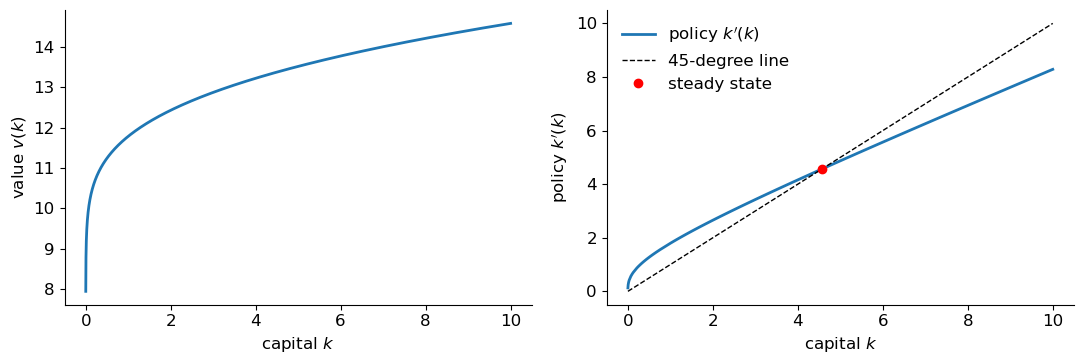

In [8]:
kp = k[g]                                   # policy function k'(k)
i_ss = np.argmin(np.abs(kp - k))            # grid point where the policy crosses the 45-degree line

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(k, v)
ax[0].set_xlabel('capital $k$'); ax[0].set_ylabel('value $v(k)$')
ax[1].plot(k, kp, label="policy $k'(k)$")
ax[1].plot(k, k, 'k--', linewidth=1, label='45-degree line')
ax[1].plot(k[i_ss], k[i_ss], 'o', color='red', label='steady state')
ax[1].set_xlabel('capital $k$'); ax[1].set_ylabel("policy $k'(k)$"); ax[1].legend(frameon=False)
plt.tight_layout();

Comments:
- $v$ is increasing and concave
- The policy $k'(k)$ is concave in a neighbourhood of zero and asymptotically linear
- The steady state level of capital is identified by the unique positive crossing of the policy and the 45-degree line

**Why is the policy function concave near zero?**

- Near $k=0$, output $Ak^\alpha$ is much larger than the capital left after depreciation, $(1-\delta)k$: their ratio $(1-\delta)k^{1-\alpha}/A$ goes to zero, and is already only 1% at $k=0.01$. So resources are approximately $Ak^\alpha$, as with full depreciation in PS1 Question 1, where the policy is $k'=\alpha\beta Ak^\alpha$
- Our policy behaves the same way: near zero it saves a roughly constant fraction of output, about a third ($k'/Ak^\alpha$ is 0.31 at $k=10^{-6}$ and 0.37 at $k=0.01$), so $k'\approx s\,Ak^\alpha$
- A power function $k^\alpha$ with $\alpha<1$ is concave: very steep near zero, since the marginal product $\alpha Ak^{\alpha-1}$ goes to infinity, and flattening fast as capital accumulates. Saving a constant fraction of it implies that the policy function is concave near zero

**Why is the policy function asymptotically linear?**

- For large $k$, output is small relative to the capital left after depreciation: $Ak^\alpha/k\to0$ since $\alpha<1$, so resources are $(1-\delta)k+Ak^\alpha\approx(1-\delta)k$. Equivalently, the marginal product of capital $\alpha Ak^{\alpha-1}$ goes to zero, and the gross return on saving goes to $1-\delta$
- So for large $k$ the planner faces an (almost) linear technology: the AK model of PS1 Question 3 with log utility ($\sigma=1$) and gross return $1-\delta$ instead of $1-\delta+A$. We know that in this case the policy is linear: consume a fraction $1-\beta$ of resources and save a fraction $\beta$, so $k'=\beta(1-\delta)k$
- Hence $k'(k)/k\to\beta(1-\delta)=0.72<1$: for large $k$ the policy lies below the 45-degree line, and capital falls
- The limit is reached slowly, and from below: the slope of the policy is about 0.67 at $k=10$, 0.69 at $k=1{,}000$ and 0.71 at $k=100{,}000$. The planner knows that capital will fall back towards $k_{ss}$, where it is productive again: this future output makes it richer than the linear technology alone suggests, so it consumes a bit more and saves a bit less. The policy is concave on our grid, but not everywhere: its slope is minimised around $k=30$, where it has value approximately equal to 0.66, and then rises towards 0.72

### Sanity check: analytical steady state

Useful sanity check: the Euler equation $1=\beta\,(1-\delta+\alpha A k^{\alpha-1})$ gives the steady state level of capital in closed form

$$
k_{ss}=\left(\frac{1/\beta-1+\delta}{\alpha A}\right)^{\frac{1}{\alpha-1}} \tag{3}
$$


In [9]:
def steady_state(params):
    beta, A, alpha, delta = params['beta'], params['A'], params['alpha'], params['delta']
    return ((1/beta - 1 + delta) / (alpha*A))**(1/(alpha - 1))     # closed form (3)

k_ss = steady_state(params)
k_ss_num = k[i_ss]
print(f'numerical: {k_ss_num:.4f}   analytical (3): {k_ss:.4f}   grid step: {k[1] - k[0]:.4f}')

numerical: 4.5600   analytical (3): 4.5608   grid step: 0.0010


### A second sanity check: full depreciation

With $\delta=1$ the model is PS1 Question 1, and we know the answer in closed form:
$$
k'=\alpha\beta A k^\alpha
$$
We copy `params` and change only $\delta$, to keep iterations quick we use 1,000 grid points

In [10]:
params_ps1 = dict(params, delta=1.0)     # same parameters, but full depreciation
k1, f1 = make_grid(1_000, params_ps1)
_, g1, _ = vfi(k1, f1, params_ps1, np.zeros(len(k1)), tol, max_iter)
closed_form = params_ps1['alpha']*params_ps1['beta']*params_ps1['A']*k1**params_ps1['alpha']   # k' = alpha*beta*A*k^alpha
print(f'max |numerical - closed form| = {np.max(np.abs(k1[g1] - closed_form)):.4f}   grid step = {k1[1] - k1[0]:.4f}')

max |numerical - closed form| = 0.0068   grid step = 0.0100


## Watching VFI converge

Same algorithm as before: on the left panel we plot the value function as it gets computed in the different iterations: first the initial guess $v_0$, then $v_n$ every 10 iterations, using progressively darker colours. To keep iterations quick we use 1,000 grid points

On the right we plot, at each iteration, the distance $\|v_n-v_{n-1}\|_\infty$, the Cauchy criterion of Step 4. It goes to zero, and we stop when it falls below `tol`. On a log scale it is close to a straight line: the contraction shrinks it by a factor of about $\beta$ per iteration.

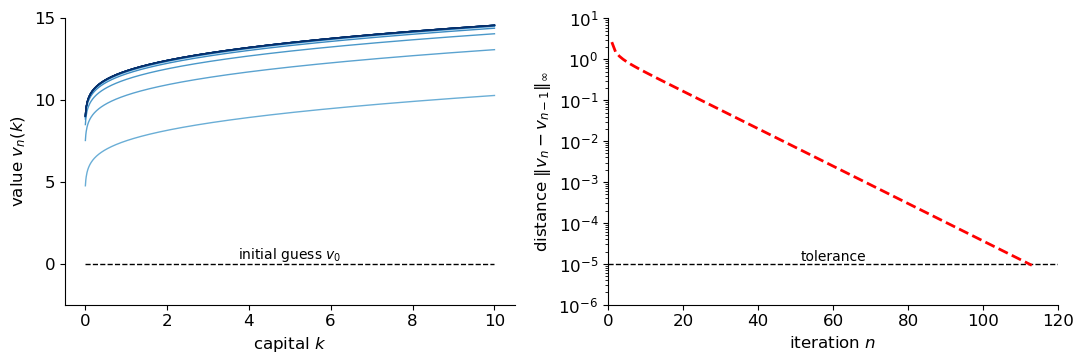

converged after 113 iterations


In [11]:
k_demo, f_demo = make_grid(1_000, params)
v_n = np.zeros(len(k_demo))                              # initial guess v_0 = 0
distances = []                                           # ||v_n - v_{n-1}|| at each iteration

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(k_demo, v_n, 'k--', linewidth=1)
ax[0].text(k_demo[len(k_demo)//2], 0, 'initial guess $v_0$', va='bottom', ha='center', fontsize=10)
ax[0].set_xlabel('capital $k$'); ax[0].set_ylabel('value $v_n(k)$')
ax[0].set_ylim(-2.5, 15)                                 # fix the axes from the start: v_0 = 0 at the same height as tol on the right
ax[0].set_yticks([0, 5, 10, 15])
ax[1].axhline(tol, color='k', linestyle='--', linewidth=1)
ax[1].text(60, tol, 'tolerance', va='bottom', ha='center', fontsize=10)
ax[1].set_yscale('log')
ax[1].set_xlim(0, 120); ax[1].set_ylim(1e-6, 10)        # VFI needs about 110 iterations here
ax[1].set_xlabel('iteration $n$'); ax[1].set_ylabel(r'distance $\|v_n-v_{n-1}\|_\infty$')
distance_line, = ax[1].plot([], [], color='red', linestyle='--')
plt.tight_layout()
display(fig)                                             # at first, only the initial guess
time.sleep(1)

for n in range(1, 1_001):
    Tv, _ = bellman(v_n, k_demo, f_demo, params)
    distances.append(np.max(np.abs(Tv - v_n)))
    v_n = Tv
    if n % 10 == 0 or distances[-1] < tol:               # update the plots every 10 iterations, and at the last one
        ax[0].plot(k_demo, v_n, color=plt.cm.Blues(0.45 + 0.55*min(n/110, 1)), linewidth=1)
        distance_line.set_data(range(1, n + 1), distances)
        clear_output(wait=True)
        display(fig)
        time.sleep(0.5)
    if distances[-1] < tol:
        break
plt.close(fig)
print(f'converged after {n} iterations')

## Q1.2 Time series from different initial conditions

20 periods from $k_0\in\{0.1,\ 1,\ 10\}$, interpolating the policy function between grid points:

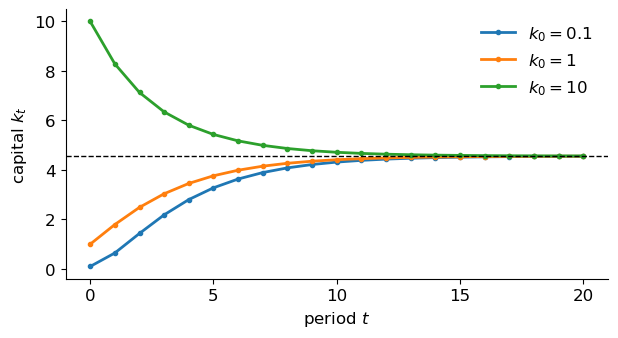

In [12]:
T = 20
paths = {}
for k0 in [0.1, 1, 10]:
    path = [k0]
    for t in range(T):
        path.append(np.interp(path[-1], k, kp)) 
    paths[k0] = np.array(path)
    plt.plot(range(T + 1), paths[k0], marker='o', markersize=3, label=f'$k_0={k0}$')
plt.axhline(k_ss, color='k', linestyle='--', linewidth=1)
plt.xticks(range(0, T + 1, 5))
plt.xlabel('period $t$'); plt.ylabel('capital $k_t$'); plt.legend(frameon=False);

## Q1.3 Convergence of income levels across countries

How fast is convergence? A standard measure is the number of periods until half of the initial gap from the steady state is closed:

In [13]:
for k0, path in paths.items():
    half_life = np.argmax(np.abs(path - k_ss) <= 0.5*abs(k0 - k_ss))
    print(f'k0 = {k0:>4}: half of the gap closed after {half_life} periods, k_20 = {path[-1]:.3f}')

k0 =  0.1: half of the gap closed after 4 periods, k_20 = 4.553
k0 =    1: half of the gap closed after 3 periods, k_20 = 4.556
k0 =   10: half of the gap closed after 2 periods, k_20 = 4.565


**Implications**
- Even very different initial capital stocks converge to $k_{ss}$ within a few periods
- If a period is about 2.5 years (an annual $\beta\approx0.96$ and $\delta\approx0.08$ give $\beta=0.9$ and $\delta=0.2$ per period), half of the initial gap closes in about 10 years, and in 50 years almost no income difference remains
- So differences in initial capital cannot explain large, *persistent* income differences across countries
- Persistent differences need differences in parameters (productivity $A$, patience $\beta$, depreciation $\delta$...) or a different model
- This is the "fast transitional dynamics" limitation of the standard model

# Question 2: Howard's policy improvement algorithm

**Idea:** the maximisation is the expensive part, so do it rarely

1. Start from $v_0=0$ and compute the optimal policy $g_0$ (the first VFI step)
2. **Policy evaluation:** with $g_0$ *fixed*, iterate $v\leftarrow \log((1-\delta)k+Ak^{\alpha}-k_{g_0})+\beta\, v\circ g_0$ until it converges: this is the value $v_1$ of following $g_0$ forever
3. **Policy improvement:** compute the optimal policy given $v_1$
4. Repeat 2–3 until the value function converges

In [14]:
def evaluate_policy(v, g, k, f, params, tol):
    u = np.log(f - k[g])                 # period utility under the fixed policy
    n = 0
    while True:
        v_new = u + params['beta']*v[g]    # no maximisation: cost ~grid_points, not ~grid_points^2
        n += 1
        if np.max(np.abs(v_new - v)) < tol:
            return v_new, n
        v = v_new

def howard(k, f, params, tol):
    v = np.zeros(len(k))
    _, g = bellman(v, k, f, params)      # step 1: g_0 from v_0 = 0
    n_max, n_eval = 1, 0
    while True:
        v_new, n = evaluate_policy(v, g, k, f, params, tol)    # step 2
        n_eval += n
        converged = np.max(np.abs(v_new - v)) < tol
        v = v_new
        if converged:
            return v, g, n_max, n_eval
        _, g = bellman(v, k, f, params)  # step 3
        n_max += 1

## Value and policy functions: VFI and Howard

We run Howard's algorithm on the same grid and plot its value and policy functions (orange, dashed) on top of those from VFI (blue)

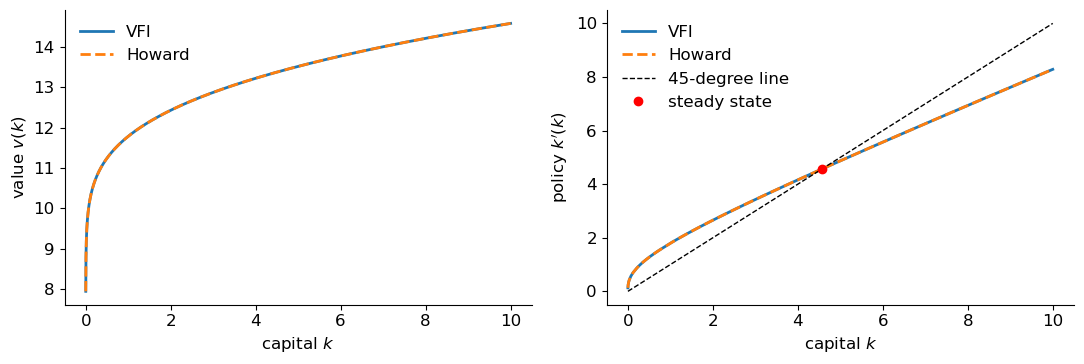

In [15]:
start = time.time()
vh, gh, n_max, n_eval = howard(k, f, params, tol)
t_howard = time.time() - start

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(k, v, label='VFI')
ax[0].plot(k, vh, '--', color='C1', label='Howard')
ax[0].set_xlabel('capital $k$'); ax[0].set_ylabel('value $v(k)$'); ax[0].legend(frameon=False)
ax[1].plot(k, k[g], label='VFI')
ax[1].plot(k, k[gh], '--', color='C1', label='Howard')
ax[1].plot(k, k, 'k--', linewidth=1, label='45-degree line')
ax[1].plot(k[i_ss], k[i_ss], 'o', color='red', label='steady state')
ax[1].set_xlabel('capital $k$'); ax[1].set_ylabel("policy $k'(k)$"); ax[1].legend(frameon=False)
plt.tight_layout();

## Same grid, same answer, much faster

In [16]:
print(f'VFI:    {len(dist):4d} maximisations                               {t_vfi:5.1f} s')
print(f'Howard: {n_max:4d} maximisations + {n_eval} policy evaluations    {t_howard:5.1f} s')
print(f'max |v_Howard - v_VFI| = {np.max(np.abs(vh - v)):.1e}')

VFI:     113 maximisations                               128.3 s
Howard:   11 maximisations + 439 policy evaluations     13.2 s
max |v_Howard - v_VFI| = 8.1e-05


**Why is Howard faster?**
- VFI: ~113 iterations, each with a maximisation ($\sim N^2$ operations)
- Howard: only ~10 maximisations; the many extra iterations are policy evaluations, which cost only $\sim N$
- More iterations in total, but most of them are cheap

# Beyond the problem set: why a grid with 10,000 points?

We solve the model with VFI and Howard on grids with 10, 100, 1,000 and 10,000 points, and compare the VFI value and policy functions, and the time to complete of both algorithms. The 10,000-point solutions are the ones computed above, so we do not need to recompute them

In [17]:
results = {}
for grid_points in [10, 100, 1_000]:
    k_N, f_N = make_grid(grid_points, params)
    start = time.time()
    v_N, g_N, _ = vfi(k_N, f_N, params, np.zeros(grid_points), tol, max_iter)
    t_vfi_N = time.time() - start
    start = time.time()
    vh_N, gh_N, _, _ = howard(k_N, f_N, params, tol)
    t_howard_N = time.time() - start
    results[grid_points] = dict(k=k_N, v=v_N, g=g_N, vh=vh_N, gh=gh_N, t_vfi=t_vfi_N, t_howard=t_howard_N)
results[10_000] = dict(k=k, v=v, g=g, vh=vh, gh=gh, t_vfi=t_vfi, t_howard=t_howard)   # computed above, no need to redo it

print(f'{"grid points":>11}  {"VFI (s)":>9}  {"Howard (s)":>10}  {"steady state":>12}')
for grid_points, r in results.items():
    k_N = r['k']
    k_ss_N = k_N[np.argmin(np.abs(k_N[r['g']] - k_N))]     # grid point closest to the crossing with the 45-degree line
    print(f'{grid_points:>11,}  {r["t_vfi"]:>9.3f}  {r["t_howard"]:>10.3f}  {k_ss_N:>12.4f}')
print(f'{"analytical":>11}  {"":>9}  {"":>10}  {k_ss:>12.4f}')

grid points    VFI (s)  Howard (s)  steady state
         10      0.001       0.001        4.0000
        100      0.008       0.002        4.5000
      1,000      0.768       0.090        4.5600
     10,000    128.325      13.192        4.5600
 analytical                               4.5608


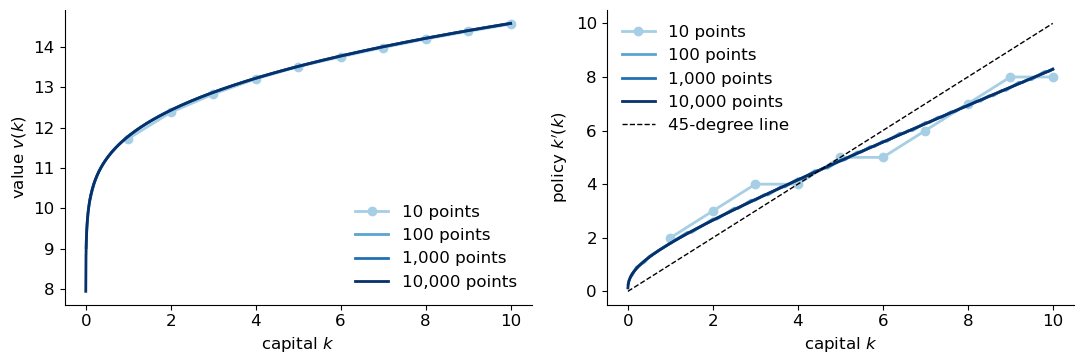

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for grid_points, shade in zip(results, [0.35, 0.55, 0.75, 1.0]):     # finer grid, darker colour
    r = results[grid_points]
    marker = 'o' if grid_points == 10 else None                      # with 10 points, show the grid points
    ax[0].plot(r['k'], r['v'], marker=marker, color=plt.cm.Blues(shade), label=f'{grid_points:,} points')
    ax[1].plot(r['k'], r['k'][r['g']], marker=marker, color=plt.cm.Blues(shade), label=f'{grid_points:,} points')
ax[1].plot(k, k, 'k--', linewidth=1, label='45-degree line')
ax[0].set_xlabel('capital $k$'); ax[0].set_ylabel('value $v(k)$'); ax[0].legend(frameon=False)
ax[1].set_xlabel('capital $k$'); ax[1].set_ylabel("policy $k'(k)$"); ax[1].legend(frameon=False, loc='upper left')
plt.tight_layout();

- **Value function:** already accurate on coarse grids. It is a bit below the 10,000-point one, since there are fewer choices, but by at most 0.5% with 10 points and 0.03% with 100: mistakes in the policy have only second-order effects on the value (envelope theorem)
- **Policy function:** this is where the grid matters. Since $k'$ can only take grid values, the policy is a step function and the steady state is pinned down only up to the grid step. With 10 points both $k=4$ and $k=5$ are fixed points, while the true $k_{ss}=4.5608$ lies in between: capital ends at 4 starting from below and at 5 starting from above. With 100 points it ends at 4.5 or 4.6, and with 1,000 points at 4.56
- To get the steady state right to three decimals we need a grid step of $0.001$, that is 10,000 points on $[0,10]$

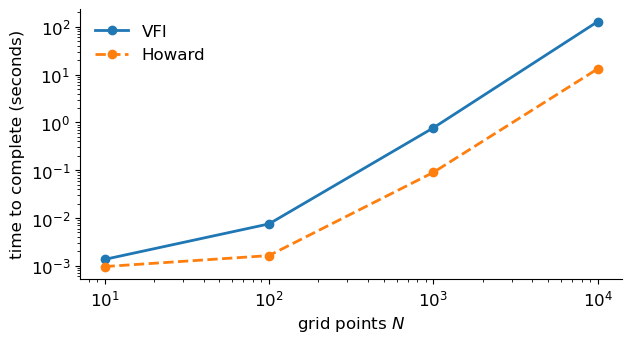

In [19]:
grid_sizes = list(results)
plt.plot(grid_sizes, [results[n]['t_vfi'] for n in grid_sizes], marker='o', label='VFI')
plt.plot(grid_sizes, [results[n]['t_howard'] for n in grid_sizes], '--', marker='o', color='C1', label='Howard')
plt.xscale('log'); plt.yscale('log')
plt.xlabel('grid points $N$'); plt.ylabel('time to complete (seconds)'); plt.legend(frameon=False);

- **Time:** each VFI iteration builds an $N\times N$ matrix, and the number of iterations does not depend on $N$, so the time grows at least with $N^2$: with 100 times more points, from 100 to 10,000, VFI takes more than $100^2=10{,}000$ times longer
- On small grids both algorithms take a few milliseconds
- Howard's maximisations are also over $N\times N$ matrices, but there are only about 10 of them: the gain is largest on fine grids, where Howard is about 10 times faster

# Beyond the problem set: other ways to speed things up

- **Policy function iteration** is what we just did: Howard's algorithm (Howard 1960). Evaluating each policy only for a fixed number of steps gives *modified policy iteration* (Puterman and Shin 1978), with VFI and full policy iteration as its two extremes
- **Exploit the structure of the solution:** the policy is increasing and the objective is concave in $k'$, so the search for each $k_i$ can start where the previous one ended and stop once the value falls
- **Coarse-to-fine grids:** solve on a coarse grid first, then search the fine grid only near the coarse policy
- **Better grids:** an evenly spaced grid (`linspace`) wastes points where the functions are nearly linear. Put more points where they curve, near zero capital, e.g. a power-spaced grid $k_i=k_{\min}+(k_{\max}-k_{\min})\left(\frac{i-1}{N-1}\right)^{\theta}$ with $\theta>1$, or a double-exponential grid
- **Approximate the value function with a polynomial** instead of a grid: Problem Set 3, Question 1 (see Judd 1998)
- **Endogenous grid method:** use the Euler equation to back out today's capital from a grid for tomorrow's, which avoids the maximisation altogether (Carroll 2006)
- **Continuous time:** finite-difference methods for the Hamilton-Jacobi-Bellman equation are very fast and accurate (Achdou, Han, Lasry, Lions and Moll 2022)
- **Compile the code:** [Numba](https://numba.pydata.org) compiles loops to machine code with a one-line decorator, often making them 10–100 times faster

# Takeaways

- **Value function iteration** converges because $T$ is a contraction with modulus $\beta$: each iteration shrinks the distance to $v^*$ by at least a factor $\beta$. The number of iterations depends on $\beta$, the tolerance and how far the initial guess is (but only through $\|v_1-v_0\|$), not on $N$
- But the time each iteration takes depends on $N$ and **maximisations are expensive**: plain VFI is $\sim N^2$ per iteration, which is slow on a fine grid
- **Howard's algorithm (policy function iteration)** does few expensive maximisations and many cheap policy evaluations: about 10 times faster here
- **Many other methods are even faster**
- **Check your code against special cases you know the solution of:** the analytical steady state, and the closed form when $\delta=1$
- **Economics:** transitional dynamics are fast, so initial conditions cannot explain persistent income differences across countries

**References**

Achdou, Y., J. Han, J.-M. Lasry, P.-L. Lions and B. Moll (2022): "Income and Wealth Distribution in Macroeconomics: A Continuous-Time Approach," *Review of Economic Studies*, 89(1), 45–86.

Carroll, C. D. (2006): "The Method of Endogenous Gridpoints for Solving Dynamic Stochastic Optimization Problems," *Economics Letters*, 91(3), 312–320.

Howard, R. A. (1960): *Dynamic Programming and Markov Processes*. Cambridge, MA: MIT Press.

Judd, K. L. (1998): *Numerical Methods in Economics*. Cambridge, MA: MIT Press.

Puterman, M. L. and M. C. Shin (1978): "Modified Policy Iteration Algorithms for Discounted Markov Decision Problems," *Management Science*, 24(11), 1127–1137.

**Running this notebook** 

Times are for a MacBook Air (Apple M2, 8 GB of RAM), where VFI on the 10,000-point grid takes about 2 minutes and the whole notebook 2–3 minutes. The notebook needs about 2.4 GB of free memory